In [13]:
import os
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import idx2numpy
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [14]:
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))

if project_root not in sys.path:
    sys.path.append(project_root)

In [15]:
from mlp_model.losses.bce_loss import BCELoss
from mlp_model.losses.cce_loss import CCELoss
from mlp_model.losses.mse_loss import MSELoss
from mlp_model.activations.relu import ReLU
from mlp_model.activations.tanh import Tanh
from mlp_model.activations.sigmoid import Sigmoid
import visualisation.classification_visualise as cl_vs
import classification_training_methods as cl_train

In [16]:
train_images_filepath = Path(project_root) / "data/mnist/train" / "train-images-idx3-ubyte"
train_labels_filepath = Path(project_root) / "data/mnist/train" / "train-labels-idx1-ubyte"

In [17]:
X = idx2numpy.convert_from_file(str(train_images_filepath))
y = idx2numpy.convert_from_file(str(train_labels_filepath))

In [18]:
X_sample, _, y_sample, _ = train_test_split(X, y, train_size=600, random_state=42, stratify=y)

In [19]:
X_train, X_val, y_train, y_val = train_test_split(X_sample, y_sample, test_size=0.2, random_state=42, stratify=y_sample)

In [20]:
X_train = X_train.reshape(X_train.shape[0], -1).astype(np.float32) / 255.0
X_val = X_val.reshape(X_val.shape[0], -1).astype(np.float32) / 255.0

## Ocena różnych architektur

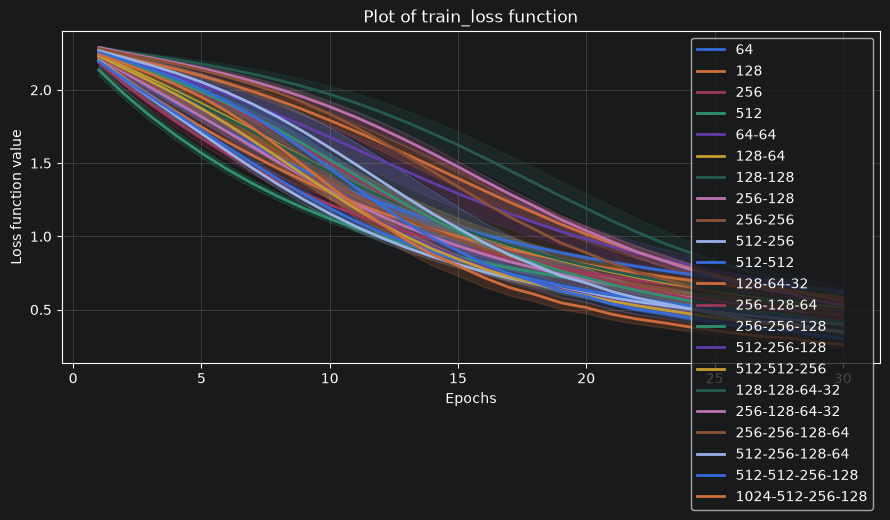

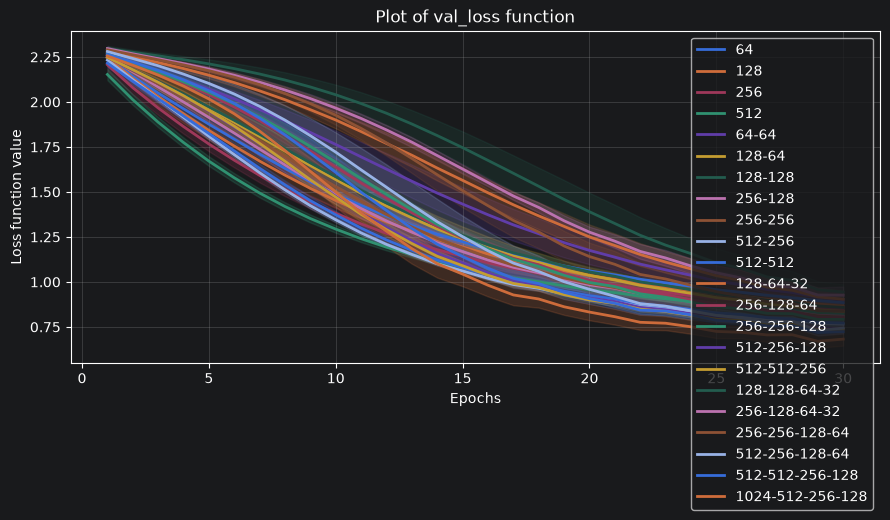

,config,loss_mean,loss_std,accuracy_mean,accuracy_std,precision_mean,precision_std,f1_score_mean,f1_score_std
0,64,0.885232,0.007445,0.745000,0.014530,0.759192,0.018374,0.739386,0.015743
1,128,0.865855,0.024000,0.736667,0.020138,0.750038,0.020146,0.730978,0.022383
2,256,0.845980,0.017214,0.755000,0.020138,0.767761,0.025083,0.751379,0.022244
3,512,0.820788,0.010898,0.766667,0.011785,0.781902,0.014778,0.763908,0.013527
4,64-64,0.900583,0.045046,0.731667,0.020683,0.740554,0.018766,0.725725,0.021002
5,128-64,0.836136,0.022010,0.748333,0.006236,0.763595,0.009311,0.743793,0.004238
6,128-128,0.858361,0.027205,0.736667,0.022730,0.751539,0.025599,0.731831,0.023447
7,256-128,0.809175,0.036210,0.753333,0.015456,0.767791,0.016054,0.749830,0.017389
8,256-256,0.804239,0.019235,0.751667,0.009718,0.763668,0.009978,0.746787,0.011355
9,512-256,0.765161,0.014356,0.778333,0.017951,0.790810,0.017970,0.775561,0.018192


In [21]:
archis = {
    "64": (64,),
    "128": (128,),
    "256": (256,),
    "512": (512,),

    "64-64": (64, 64),
    "128-64": (128, 64),
    "128-128": (128, 128),
    "256-128": (256, 128),
    "256-256": (256, 256),
    "512-256": (512, 256),
    "512-512": (512, 512),

    "128-64-32": (128, 64, 32),
    "256-128-64": (256, 128, 64),
    "256-256-128": (256, 256, 128),
    "512-256-128": (512, 256, 128),
    "512-512-256": (512, 512, 256),

    "128-128-64-32": (128, 128, 64, 32),
    "256-128-64-32": (256, 128, 64, 32),
    "256-256-128-64": (256, 256, 128, 64),
    "512-256-128-64": (512, 256, 128, 64),
    "512-512-256-128": (512, 512, 256, 128),
    "1024-512-256-128": (1024, 512, 256, 128),
}

trainings = {}

for name, hidden_sizes in archis.items():
    trainings[name] = cl_train.run_training(hidden_sizes=hidden_sizes, X_train=X_train, y_train=y_train, X_val=X_val,
                                            y_val=y_val, activation_hidden=ReLU(), epochs=30,
                                            loss_cls=CCELoss(), learning_rate=0.01, classes_count=10)

cl_vs.plot_loss(trainings, "train_loss")
cl_vs.plot_loss(trainings, "val_loss")

display(cl_train.summarize_results(trainings))